# Descriptive analysis of Digikala reviews

This notebook is the data audit of the project. Before any model is trained, it answers three questions:

1. Was the data read completely and correctly?
2. What is wrong with it, and what was done about each problem?
3. What does the data look like, and what does that mean for the modeling choices?

All counts use the full data: either the raw file (6,156,289 reviews) or the cleaned table (6,151,970 reviews),
and each table says which. When a table or plot uses a sample, the cell gives the sampling rule and the seed.

The heavy lifting lives in `src/digikala_reviews/` and `scripts/`. This notebook loads their outputs,
runs a few extra checks with pandas, and explains the results.

## Key findings

1. The data was read completely: 6,156,289 reviews, and both parsers give the same count.
2. Missing values are stored as the text `nan`. The review body is missing in only 845 reviews.
3. 3,226 review ids are duplicated; 245 of them disagree on text, rating or label and are removed. 6,151,970
   reviews remain after cleaning.
4. **A rating of 0 means "no rating recorded".** Zero-rated reviews are 80% `recommended`, and zeros jump from a
   few percent to 17-41% of monthly reviews in late 1397, then fall below 2% by mid-1401. They get no rating
   band but stay for the recommendation task. Counting them as `low` would have made almost half of that band
   wrong.
5. Missing recommendation labels follow a pattern: every non-buyer review lacks one, and 64% of all unlabeled
   reviews come from 1401 alone.
6. Both targets are imbalanced: `recommended` is 67.6% of reviews and `low` only 9.1%.
7. Reviews are concentrated on few products (the top 10% of products hold 67% of reviews), and collection was
   capped at about 200 reviews per product. The data must be split by product.
8. Reviews are short (median 6 words, 95% within 32), so a short Transformer input is enough.
9. 37% of reviews share their exact text with another review, often on other products. Identical texts mostly
   carry the same label: the accuracy ceiling for a text-only model is 97.5% for recommendation and 94.6% for
   rating bands, and less on one- or two-word reviews.
10. Negation words are a strong signal in a 1M-review sample (42% of `not_recommended` reviews against 9% of `recommended`) and are
    kept. Repeated letters and Arabic letter forms call for a light normalization step.
11. Only six product groups are covered (beauty, books, clothing, toys, travel and local goods), with no
    electronics or appliances.

## Contents

1. Reading the data
2. Quality gate
3. Cleaning
4. Three questions before defining the targets (zero ratings, fractional ratings, missing labels)
5. Descriptive statistics (size, targets, text length, repetition, concentration)
6. Vocabulary (characters, distinctive words, negation, product categories)
7. Decisions for the next stages

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from digikala_reviews import plotting
from digikala_reviews.config import (
    COMMENTS_CLEAN_PARQUET,
    COMMENTS_RAW_DIR,
    EXCLUDED_ROWS_PARQUET,
    REPORTS_DIR,
)
from digikala_reviews.quality import is_missing

plotting.apply_style()
pd.set_option("display.max_colwidth", 80)
# Whole numbers are shown without decimals, everything else with two
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,.2f}")


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


ingest = load_report("data_ingest.json")
gate = load_report("quality_gate.json")
cleaning = load_report("cleaning_report.json")

## 1. Reading the data

The dataset is the public [Digikala comments and products](https://huggingface.co/datasets/RadeAI/Digikala_comments_products)
dump on Hugging Face: one CSV of reviews and one CSV of products.

`scripts/build_parquet.py` converts both files to Parquet with pandas. Every column is read as **text** and
pandas' automatic missing-value detection is turned off, so nothing is converted or dropped silently at this
point; type checks happen in the quality gate. Review bodies can contain line breaks, so records are counted
with a real CSV parser, not by counting lines. To be sure nothing was lost, the records are counted twice, with
pandas and with Python's own `csv` module, and the SHA-256 of each file is recorded so anyone can check they have
exactly the same data.

In [2]:
pd.DataFrame(
    [
        {
            "file": f["csv_file"],
            "rows (pandas)": f["rows_pandas"],
            "rows (csv module)": f["rows_csv_module"],
            "CSV (MB)": round(f["csv_size_bytes"] / 1e6),
            "Parquet (MB)": round(f["parquet_size_bytes"] / 1e6),
            "sha256": f["csv_sha256"][:16] + "...",
        }
        for f in ingest["files"]
    ]
).set_index("file")

,rows (pandas),rows (csv module),CSV (MB),Parquet (MB),sha256
file,,,,,
digikala-comments.csv,6156289,6156289,1279,451,c7a8aa3020334fde...
digikala-products.csv,1283496,1283496,259,47,0f646e1b0ba5a075...


Both counts agree: **6,156,289 reviews** and **1,283,496 product rows**, and pandas raised no parsing error.
The project brief mentions "about 7 million" reviews; the real number is 6.16 million.
The Parquet copy is about 3x smaller than the CSV and much faster to query, so everything below reads from it.

## 2. Quality gate

`scripts/run_quality_gate.py` checks the schema, missing values, numeric columns, label vocabulary, dates and
duplicates. It does not change anything: it only counts problems and keeps examples.

One thing showed up immediately: in this CSV, missing values are written as the literal text `nan`
(the file was exported with pandas). So throughout the project a value counts as **missing** when it is blank,
contains only whitespace or invisible characters, or equals `nan`.

### 2.1 Schema

In [3]:
schema = gate["comments"]["schema"]
print("Columns:", ", ".join(schema["columns"]))
print("Missing expected columns:", schema["missing_expected"] or "none")
print("Unexpected columns:", schema["unexpected"] or "none")

Columns: id, title, body, created_at, rate, recommendation_status, is_buyer, product_id, advantages, disadvantages, likes, dislikes, seller_title, seller_code, true_to_size_rate
Missing expected columns: none
Unexpected columns: none


All 15 expected columns are present. Only `body` is used as model input. `rate` and `recommendation_status`
are targets, and `product_id` is used only to split the data by product. The rest is kept for the audit.

### 2.2 Missing values

In [4]:
missing = pd.DataFrame(gate["comments"]["missing_values"]).T[["blank", "nan_token", "missing", "missing_pct"]]
missing = missing.sort_values("missing_pct", ascending=False)
missing

,blank,nan_token,missing,missing_pct
true_to_size_rate,0,"6,065,516","6,065,516",98.53
disadvantages,0,"5,744,017","5,744,017",93.30
advantages,0,"5,448,084","5,448,084",88.50
title,"3,241","2,865,062","2,868,303",46.59
recommendation_status,0,"894,426","894,426",14.53
seller_title,0,"302,181","302,181",4.91
seller_code,0,"302,181","302,181",4.91
body,208,637,845,0.01
rate,0,0,0,0
created_at,0,0,0,0


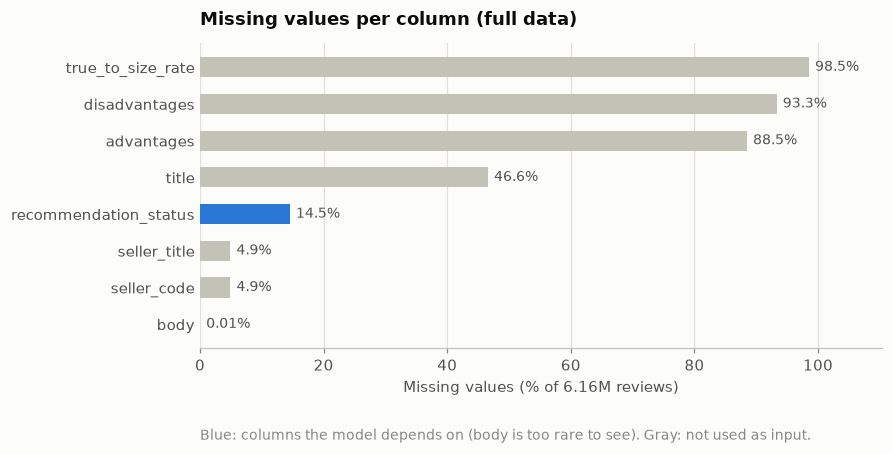

In [60]:
model_columns = {"body", "rate", "recommendation_status", "product_id"}
shown = missing[missing["missing_pct"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.6))
plotting.hbar(
    ax,
    labels=list(shown.index),
    values=list(shown["missing_pct"]),
    colors=[plotting.SERIES[0] if c in model_columns else plotting.NEUTRAL for c in shown.index],
    value_labels=[f"{p:.2f}%" if p < 1 else f"{p:.1f}%" for p in shown["missing_pct"]],
    xlabel="Missing values (% of 6.16M reviews)",
)
ax.set_title("Missing values per column (full data)")
ax.text(
    0,
    -0.3,
    "Blue: columns the model depends on (body is too rare to see). Gray: not used as input.",
    transform=ax.transAxes,
    color=plotting.MUTED,
    fontsize=9,
)
plotting.save(fig, "missing_values")
plt.show()

- `body`, the only model input, is missing in just **845** reviews (0.01%): 637 are `nan` and 208 contain only
  whitespace or invisible characters. pandas would not flag the whitespace-only ones.
- `recommendation_status` is missing in **14.5%** of reviews (894,426). These are naturally unlabeled reviews,
  not errors. They still have a rating, so they stay useful for the rating-band task.
- `rate` and `product_id` are never missing.
- `title`, `advantages`, `disadvantages` and `true_to_size_rate` are largely empty, but none of them may be used
  as features, so this does not affect the models.

### 2.3 Is the missing seller information random?

`seller_title` and `seller_code` are missing in exactly 302,181 reviews, which is also the number of reviews
written by non-buyers. A quick cross-tab checks whether the two are the same rows.

In [6]:
sellers = pd.read_parquet(COMMENTS_RAW_DIR, columns=["is_buyer", "seller_code"])
pd.crosstab(sellers["is_buyer"], is_missing(sellers["seller_code"]).rename("seller missing"), margins=True)

seller missing,False,True,All
is_buyer,,,
False,0,302181,302181
True,5854108,0,5854108
All,5854108,302181,6156289


Every non-buyer review has no seller, and every buyer review has one. The missing seller is **structural**
(no purchase, so no seller), not random. The same question for missing recommendation labels is analyzed
in section 4.

### 2.4 Labels, ratings and dates

The tables in this subsection use the raw file, before cleaning.

In [7]:
labels = pd.Series(gate["comments"]["recommendation_status"]["observed"], name="reviews").to_frame()
labels["pct"] = 100 * labels["reviews"] / labels["reviews"].sum()
labels

,reviews,pct
recommended,4162839,67.62
nan,894426,14.53
no_idea,594121,9.65
not_recommended,504903,8.20


The recommendation column uses exactly the three canonical classes plus `nan`. There are no Persian labels,
alternative spellings or extra categories, so the label mapping is the identity.

In [8]:
rate = gate["comments"]["rate"]
pd.Series(
    {
        "not a number": rate["not_a_number"],
        "inside [0, 5]": rate["in_range"],
        "outside [0, 5]": rate["out_of_range"],
        "exactly 0": rate["zero"],
        "fractional (e.g. 4.5)": rate["fractional"],
        "distinct values": rate["distinct_values"],
    },
    name="reviews",
).to_frame()

,reviews
not a number,0
"inside [0, 5]",6156288
"outside [0, 5]",1
exactly 0,529098
fractional (e.g. 4.5),228128
distinct values,177


In [9]:
pd.DataFrame(rate["out_of_range_examples"])

,src_row,id,product_id,rate,recommendation_status,body
0,4369260,38631814,5095301,2500.0,recommended,کوچک و با کیفیت


Every rating is a valid number. Only **one** falls outside 0 to 5: a rating of 2500 on a short positive review.
It could be a typo for 2.5, but guessing would be inventing data, so it is marked invalid for the rating-band
task and kept for the recommendation task.

Two numbers need a closer look later: **529,098 ratings of exactly 0** and **228,128 fractional ratings**.
Both are analyzed in section 4, because they directly affect how the `low` band should be defined.

In [10]:
dates = gate["comments"]["created_at"]
print("Rows not matching 'day month year':", dates["not_matching_format"])
print("Unknown month names:", dates["unknown_month"])
pd.Series(dates["rows_per_year"], name="reviews").to_frame().T

Rows not matching 'day month year': 0
Unknown month names: 0


,1395,1396,1397,1398,1399,1400,1401,1402
reviews,3575,6357,16693,138645,684321,1253484,2165894,1887320


Dates are Persian (Jalali) text such as `23 شهریور 1402`. All 6.16M dates have a valid format and month name,
and they span the years **1395 to 1402** (roughly 2016 to early 2024). Most reviews were written in 1400 to 1402.

### 2.5 Duplicate ids

In [11]:
dup = gate["comments"]["duplicate_ids"]
pd.Series(
    {
        "ids that appear more than once": dup["duplicated_ids"],
        "extra rows": dup["extra_rows"],
        "groups: all copies identical": dup["groups_fully_identical"],
        "groups: only metadata differs (likes, seller, ...)": dup["groups_metadata_only"],
        "groups: body, rating or label differs": dup["groups_content_differs"],
    },
    name="count",
).to_frame()

,count
ids that appear more than once,3226
extra rows,3229
groups: all copies identical,1318
"groups: only metadata differs (likes, seller, ...)",1663
"groups: body, rating or label differs",245


In [12]:
pd.DataFrame(dup["content_conflict_examples"])

,src_row,id,product_id,rate,recommendation_status,likes,body
0,3561860,12862914,2670905,5.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
1,3996799,12862914,2670905,0.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
2,2831183,17111330,2952419,0.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
3,2868980,17111330,2952419,1.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
4,3715097,22662971,853680,5.0,recommended,0,خوب بودخرید رو توصیه میکنم
5,3965442,22662971,853680,0.0,recommended,0,خوب بود
6,304459,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته
7,3835164,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته.حساسیت زا هم نیستن.


3,226 ids appear more than once. Most groups are harmless: either the copies are identical, or only counters
like `likes` differ, which suggests the data was scraped more than once. But **245 groups disagree on the
content itself**. In the examples above, the same review text has a rating of 5 in one copy and 0 in the other,
while the label stays `recommended`. That is a first hint that a rating of 0 may mean "no rating recorded"
rather than a bad rating.

Copies are compared after stripping surrounding whitespace, so a trailing line break alone does not count as
a difference.

### 2.6 Products file

In [13]:
products = gate["products"]
pd.Series(
    {
        "product rows": products["rows"],
        "distinct product ids": products["distinct_ids"],
        "ids with more than one row": products["ids_with_several_rows"],
        "ids with conflicting categories": products["ids_with_conflicting_category"],
        "products that have reviews": products["reviewed_products"],
        "reviewed products missing from the file": products["reviewed_products_missing_from_file"],
    },
    name="count",
).to_frame()

,count
product rows,1283496
distinct product ids,948352
ids with more than one row,258718
ids with conflicting categories,757
products that have reviews,331599
reviewed products missing from the file,0


The products file has repeated rows (up to 11 per id), but every reviewed product is in it. It is only used to
attach a category to each product for later error analysis, never as a model feature. When a product has
several rows, the most frequent category is used (ties are broken alphabetically, see section 6.6). 757 product
ids have more than one value in `Category1` or `sub_category`.

## 3. Cleaning

`scripts/build_clean.py` applies the rules below and writes `data/interim/comments_clean.parquet`.
The review text is copied unchanged; normalization is done later, in one shared function.

| Rule | Problem | Decision | Why |
|---|---|---|---|
| P1 | How missing values look | blank, whitespace only, or `nan` | Evidence from the quality gate |
| P2 | Empty review body (845) | Excluded from all tasks | The text is the only input |
| P3 | Missing recommendation label | Kept; used for rating band only | Required by the project brief |
| P4 | Rating outside 0 to 5 (1) | Rating band left empty; row kept | No silent correction |
| P5 | Identical copies of an id | Keep the first copy | No information lost |
| P6 | Copies differing only in metadata | Keep the first copy | Metadata is not used |
| P7 | Copies disagreeing on text, rating or label | Exclude all copies | The true label is unknown |
| P8 | Rating of exactly 0 | Rating band left empty; row kept | 0 means "no rating recorded" (section 4) |

Every excluded row is saved with its reason in `data/interim/excluded_rows.parquet`.

In [14]:
steps = pd.Series({"raw rows": cleaning["rows_raw"]})
for reason, n in cleaning["rows_excluded"].items():
    steps[f"excluded: {reason}"] = -n
steps["clean rows"] = cleaning["rows_clean"]
steps.to_frame("rows")

,rows
raw rows,6156289
excluded: duplicate_id_extra_copy,-2984
excluded: missing_body,-845
excluded: duplicate_id_conflict,-490
clean rows,6151970


In [15]:
# The first two excluded rows for each reason
excluded = pd.read_parquet(EXCLUDED_ROWS_PARQUET)
excluded.groupby("exclusion_reason").head(2).sort_values("exclusion_reason")

,src_row,id,exclusion_reason
2,9764,52238912,duplicate_id_conflict
4,14206,53498321,duplicate_id_conflict
23,91337,6474081,duplicate_id_extra_copy
29,104126,54460135,duplicate_id_extra_copy
0,6148,20431507,missing_body
1,8758,45984959,missing_body


After cleaning, **6,151,970 reviews** remain, each id exactly once (the script checks this and stops if any
duplicate is left).

Every rating of exactly 0 is flagged with `rate_is_zero`. Section 4 shows that a 0 means "no rating recorded",
so for the rating-band task these reviews get no band (`RATE_ZERO_POLICY = "invalid"` in `config.py`).
They stay in the data for the recommendation task. The table compares the bands under both rules.

In [16]:
from digikala_reviews.clean import rating_band

clean = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["rate", "rating_band"])
bands = pd.DataFrame(
    {
        "0 counted as low (as written)": rating_band(clean["rate"], zero_policy="low").fillna("no band"),
        "0 = no rating (used here)": clean["rating_band"].fillna("no band"),
    }
)
bands = bands.apply(pd.Series.value_counts).loc[["low", "medium", "high", "no band"]]
bands

,0 counted as low (as written),0 = no rating (used here)
low,1091627,562713
medium,1058360,1058360
high,4001982,4001982
no band,1,528915


Under the bands as written in the project brief, the 528,914 zeros would have been `low`: almost **half of that band**.
After the decision in section 4 they have no band instead, and `low` keeps the 562,713 reviews with a real
rating below 2.5.

## 4. Three questions before defining the targets

Section 2 left three open questions that affect how the targets are built:

1. What does a rating of **0** mean: a very bad rating, or no rating at all?
2. Where do the **fractional ratings** (4.25, 3.8, ...) come from?
3. Are **missing recommendation labels** random, or do they follow a pattern?

Each question is checked from several angles. All tables use the full cleaned table
without the single rating of 2500 (6,151,969 reviews), unless a cell says otherwise.

In [17]:
import numpy as np

from digikala_reviews.dates import parse_jalali

reviews = pd.read_parquet(
    COMMENTS_CLEAN_PARQUET,
    columns=["product_id", "rate", "recommendation", "is_buyer", "created_at_jalali"],
)
reviews = reviews[reviews["rate"] <= 5].copy()  # drop the single rating of 2500
reviews["recommendation"] = reviews["recommendation"].fillna("missing")
reviews[["year", "month"]] = parse_jalali(reviews["created_at_jalali"])

# Whole ratings keep their value as a label; everything else is "fractional"
whole = reviews["rate"] % 1 == 0
reviews["rate_group"] = "fractional"
reviews.loc[whole, "rate_group"] = reviews.loc[whole, "rate"].astype(int).astype(str)

RATE_GROUPS = ["0", "1", "2", "3", "4", "5", "fractional"]
LABELS = ["recommended", "no_idea", "not_recommended", "missing"]
reviews["rate_group"].value_counts().loc[RATE_GROUPS].to_frame("reviews")

,reviews
rate_group,
0,528914
1,327322
2,197917
3,958144
4,1514685
5,2396960
fractional,228027


### 4.1 Rating vs recommendation label

If 0 meant "very bad", reviews rated 0 should look like reviews rated 1: mostly `not_recommended`.

In [18]:
by_rate = pd.crosstab(reviews["rate_group"], reviews["recommendation"], normalize="index") * 100
by_rate = by_rate.loc[RATE_GROUPS, LABELS]
by_rate

recommendation,recommended,no_idea,not_recommended,missing
rate_group,,,,
0,80.47,3.89,10.85,4.79
1,3.71,6.50,77.32,12.48
2,9.84,27.58,47.17,15.42
3,44.73,38.19,6.32,10.75
4,78.41,5.52,0.39,15.67
5,81.00,0.61,0.26,18.12
fractional,63.60,14.42,12.17,9.81


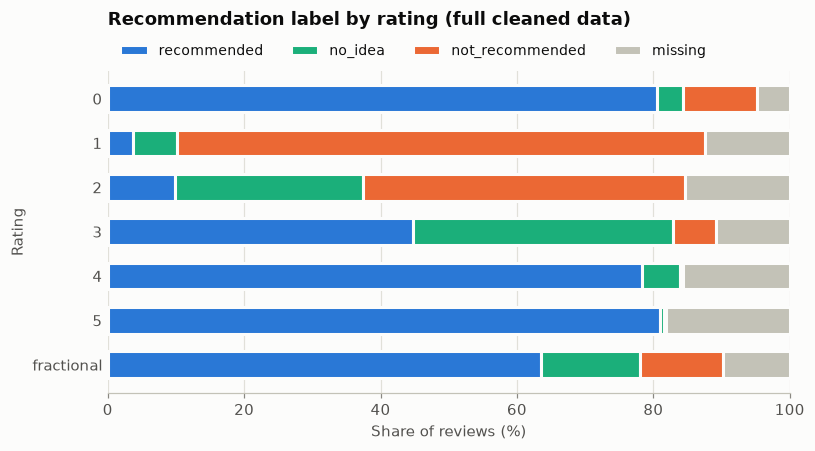

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plotting.stacked_hbar(ax, by_rate, plotting.RECOMMENDATION_COLORS)
ax.set_title("Recommendation label by rating (full cleaned data)", pad=30)
ax.set_ylabel("Rating")
plotting.save(fig, "label_by_rating")
plt.show()

### 4.2 Zero and fractional ratings over time

If zeros were ordinary bad ratings, their share should be roughly stable over time.
A sudden change points to a change in how the site recorded ratings. Months with fewer than 1,000 reviews are
left out because their shares are noisy, so the horizontal axis skips them.

In [20]:
monthly = reviews.groupby(["year", "month"]).agg(
    reviews=("rate", "size"),
    zero_pct=("rate", lambda r: 100 * (r == 0).mean()),
    fractional_pct=("rate_group", lambda g: 100 * (g == "fractional").mean()),
)
monthly = monthly[monthly["reviews"] >= 1000]  # very small months give noisy shares
monthly.index = [f"{y}-{m:02d}" for y, m in monthly.index]
monthly.head(3)

,reviews,zero_pct,fractional_pct
1397-03,1039,4.72,50.43
1397-05,1066,2.53,46.06
1397-06,1034,2.80,46.03


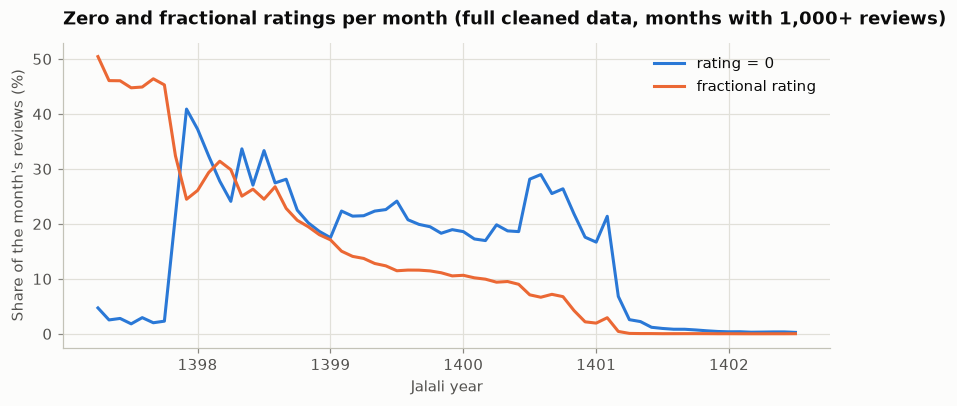

In [21]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = range(len(monthly))
ax.plot(x, monthly["zero_pct"], color=plotting.SERIES[0], label="rating = 0")
ax.plot(x, monthly["fractional_pct"], color=plotting.SERIES[1], label="fractional rating")

year_starts = [i for i, label in enumerate(monthly.index) if label.endswith("-01")]
ax.set_xticks(year_starts, [monthly.index[i][:4] for i in year_starts])
ax.set_ylabel("Share of the month's reviews (%)")
ax.set_xlabel("Jalali year")
ax.legend(loc="upper right")
ax.set_title("Zero and fractional ratings per month (full cleaned data, months with 1,000+ reviews)")
plotting.save(fig, "zero_fractional_over_time")
plt.show()

### 4.3 Buyers vs non-buyers

In [22]:
buyer_zero = reviews.groupby("is_buyer")["rate"].agg(
    reviews="size",
    zero_pct=lambda r: 100 * (r == 0).mean(),
)
buyer_zero

,reviews,zero_pct
is_buyer,,
False,301906,4.77
True,5850063,8.79


Buyers have more zeros than non-buyers. This does not point to either reading of a 0, so it is not used as
evidence below.

### 4.4 What do the texts say?

A rough signal from the words people use. The check counts reviews that contain a clearly positive
word (`عالی`, "excellent") or a clearly negative one (`افتضاح`, `ناراضی`, `پشیمون`, `بی کیفیت`, ...).
Short or ambiguous words like `خوب` or `بد` are left out on purpose: `بد` also appears inside `بدون` ("without").

To keep memory low while the section 4 tables are loaded, this uses **300,000 reviews**: a simple random sample without replacement from the cleaned table (the single rating of 2500 dropped), drawn with `DataFrame.sample(n, random_state=2026)`.

In [23]:
texts = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["body", "rate"])
texts = texts[texts["rate"] <= 5].sample(300_000, random_state=2026)
texts["rate_group"] = reviews.loc[texts.index, "rate_group"]

POSITIVE = "عالی"
NEGATIVE = "افتضاح|ناراضی|پشیمون|پشیمان|بی کیفیت|بیکیفیت|بی\u200cکیفیت"
texts["positive"] = texts["body"].str.contains(POSITIVE)
texts["negative"] = texts["body"].str.contains(NEGATIVE)

words = texts.groupby("rate_group")[["positive", "negative"]].mean() * 100
words.columns = ["has positive word (%)", "has negative word (%)"]
words.loc[RATE_GROUPS]

,has positive word (%),has negative word (%)
rate_group,,
0,16.58,1.39
1,1.27,12.60
2,2.38,5.08
3,5.24,0.88
4,9.75,0.26
5,32.91,0.36
fractional,13.95,2.38


### 4.5 Reading examples

Fifteen reviews rated 0, drawn from the 300,000-review sample above with `sample(15, random_state=2026)`, with their recommendation label.

In [24]:
# Taken from the 300,000-review text sample above
zero_examples = texts[texts["rate"] == 0].sample(15, random_state=2026)
zero_examples = zero_examples.join(reviews[["recommendation", "is_buyer", "created_at_jalali"]])
zero_examples["body"] = zero_examples["body"].str[:150]
zero_examples[["recommendation", "is_buyer", "created_at_jalali", "body"]]

,recommendation,is_buyer,created_at_jalali,body
3346640,recommended,True,8 شهریور 1400,فیلتر خوبی ب نظر میرسه ببینیم چقدر کار میکنه من بدون تفلن بستم همراهش ی واشر...
2384147,recommended,True,27 مهر 1400,کتاب بسیار خواندنی
3993965,recommended,True,26 فروردین 1399,قبلاً برندهای زیادی بودن که دستمال آرایش پاک کن پوست حساس و خشک داشتن اما ال...
4906585,recommended,True,21 تیر 1400,خیلی خوب و بموقع به دستم رسید
883051,recommended,True,15 آذر 1400,اولین کتاب از چهارگانه جان فانته
1887332,recommended,True,11 مهر 1400,خیلی خوبه . انواع لباس های نازک دوز رو داره
373273,missing,True,12 اردیبهشت 1401,فوق العاده
679252,recommended,True,9 مهر 1401,من استفاده کردم راضیم.البته برای هر مویی شاید خوب نباشد
5863612,recommended,True,25 تیر 1400,خوبه دیگه برای تقویت استدلال
3055109,recommended,True,16 اسفند 1400,من چون تعریفش رو شنیده بودم خریدم\r\nحالت رومانی داره


### 4.6 Fractional ratings

Which fractional values occur? Steps of 0.25 (4.25, 3.75) suggest an average of four sub-scores,
steps of 0.2 (4.2, 3.8) an average of five.

In [25]:
fractional = reviews.loc[reviews["rate_group"] == "fractional", "rate"]
step = np.select(
    [np.isclose((fractional * 4) % 1, 0), np.isclose((fractional * 5) % 1, 0)],
    ["multiple of 0.25", "multiple of 0.2"],
    default="other",
)
print(pd.Series(step).value_counts())
fractional.value_counts().head(10).to_frame("reviews")

multiple of 0.25    85696
multiple of 0.2     85420
other               56911
Name: count, dtype: int64


,reviews
rate,
4.50,13471
3.50,12205
4.25,11650
3.75,10044
4.20,9840
3.80,8739
4.40,8673
4.75,8287
4.60,8150


### 4.7 Are missing recommendation labels random?

The share of reviews without a label, split by buyer status, rating, product popularity and year.
If the label were missing at random, all these shares would be close to the overall 14.5%.

In [26]:
reviews["label_missing"] = reviews["recommendation"] == "missing"

reviews_per_product = reviews.groupby("product_id")["rate"].transform("size")
reviews["product_popularity"] = pd.cut(
    reviews_per_product,
    bins=[0, 1, 10, 100, 1000, np.inf],
    labels=["1 review", "2-10", "11-100", "101-1000", "1000+"],
)

for column in ["is_buyer", "rate_group", "product_popularity", "year"]:
    share = reviews.groupby(column, observed=True)["label_missing"].agg(reviews="size", missing_pct="mean")
    share["missing_pct"] *= 100
    print(f"\n{column}")
    print(share.to_string())


is_buyer
          reviews  missing_pct
is_buyer                      
False      301906          100
True      5850063        10.12

rate_group
            reviews  missing_pct
rate_group                      
0            528914         4.79
1            327322        12.48
2            197917        15.42
3            958144        10.75
4           1514685        15.67
5           2396960        18.12
fractional   228027         9.81

product_popularity
                    reviews  missing_pct
product_popularity                      
1 review              91982        20.31
2-10                 634902        18.43
11-100              2330730        15.41
101-1000            3094355        12.89

year
      reviews  missing_pct
year                      
1395     3561        97.11
1396     6341        97.40
1397    16660        48.02
1398   138525        13.45
1399   684132         5.63
1400  1253096         4.78
1401  2164887        26.28
1402  1884767        10.10


In [27]:
# Shares hide volume: where do the unlabeled reviews actually come from?
unlabeled = reviews[reviews["label_missing"]]
volume = unlabeled["year"].value_counts().sort_index().to_frame("unlabeled reviews")
volume["share of all unlabeled (%)"] = 100 * volume["unlabeled reviews"] / len(unlabeled)
non_buyer_pct = 100 * (~unlabeled["is_buyer"]).mean()
print(f"Unlabeled reviews: {len(unlabeled):,}, written by non-buyers: {non_buyer_pct:.1f}%")
volume

Unlabeled reviews: 893,858, written by non-buyers: 33.8%


,unlabeled reviews,share of all unlabeled (%)
year,,
1395,3458,0.39
1396,6176,0.69
1397,8000,0.89
1398,18630,2.08
1399,38489,4.31
1400,59891,6.70
1401,568916,63.65
1402,190298,21.29


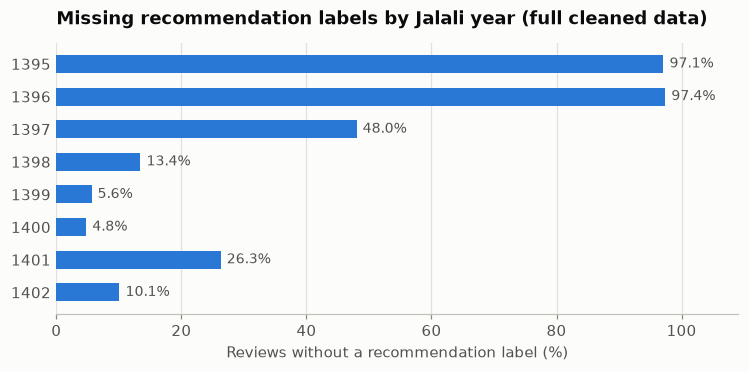

In [28]:
by_year = reviews.groupby("year")["label_missing"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.2))
plotting.hbar(
    ax,
    labels=[str(y) for y in by_year.index],
    values=list(by_year),
    value_labels=[f"{v:.1f}%" for v in by_year],
    xlabel="Reviews without a recommendation label (%)",
)
ax.set_title("Missing recommendation labels by Jalali year (full cleaned data)")
plotting.save(fig, "missing_labels_by_year")
plt.show()

### 4.8 Findings

**A rating of 0 means "no rating recorded", not "very bad".** Five checks point the same way:

- 80% of zero-rated reviews are `recommended`, about the same as ratings of 4 and 5, while reviews rated 1 are
  77% `not_recommended`.
- Zeros make up a few percent of reviews before late 1397, then jump to 17-41% of each month's reviews, and fall
  below 2% by mid-1401. Real bad ratings would not switch on and off like that; it looks like a change in how
  the site stored ratings.
- The positive word appears in 16.6% of zero-rated texts, between the 4-star (9.8%) and 5-star (32.9%) levels and
  far above ratings of 1 to 3. Negative words appear in 1.4%, much less than for a rating of 1 (12.6%).
- Most of the 15 sampled zero-rated reviews are positive and none is negative.
- Some duplicated reviews have a 5 in one copy and a 0 in the other (section 2.5).

The dataset card on Hugging Face (checked on 2026-10-24) does not document the columns, so the decision rests on this evidence. About 11% of zeros are `not_recommended`, so a few may be
genuinely bad, but without a recorded rating there is no way to tell them apart.

**Decision:** for the rating-band task, a rating of 0 is treated as missing (`RATE_ZERO_POLICY = "invalid"`).
These reviews stay in the data and are still used for the recommendation task. The `low` band drops the 528,914
zero ratings, which were almost half of it, and keeps the 562,713 reviews with a real rating below 2.5. This
change to the bands was reviewed and approved before any modeling. The baseline models will also be trained under
the original rule and both results reported, but that comparison does not change the decision. The zero-rated
reviews can later serve as an unlabeled pool for pseudo-labeling the rating band, on the training split only.

**Fractional ratings are most likely real ratings from an older rating system.** Three quarters of them are
multiples of 0.25 or 0.2, which fits an average of several sub-scores; the rest are not explained. They make up
about half of the reviews in early 1397 and fade out by 1401. They lie inside [0, 5], so the bands apply to them
unchanged. Values close to a band edge (for example 3.8, which is `medium`) are worth a look in the error analysis.

**Missing recommendation labels are not missing at random.**

- Every review written by a non-buyer (301,906) has no label; only 10% of buyer reviews lack one.
- The share of unlabeled reviews is very high in 1395-1396 (97%), but those years are small. By volume, 64% of all
  unlabeled reviews (568,916) come from 1401, and 21% from 1402.
- Only 34% of unlabeled reviews are by non-buyers; the other 66% are buyer reviews. Reviews from 1401 are 26%
  unlabeled, against about 5% in 1399-1400. 1401 is also when the zero ratings stop, so a change on the site may
  explain both; this stays an open question.
- Reviews of less popular products miss the label more often (20% against 13%).

So naturally unlabeled reviews are not a random sample of the labeled ones. The main semi-supervised experiment
therefore uses the random mask defined in the project brief, and the naturally unlabeled reviews are only an optional extension.

**Side note:** the product-popularity table has no product with more than 1,000 reviews. Section 5.1 shows the
real limit is much lower, about 200 reviews per product.

## 5. Descriptive statistics

This section completes the descriptive analysis required by the project brief (A1 to A5). Parts of it were
already covered above (row counts, missing values, duplicate ids); here the remaining pieces are added.

Everything uses the **full cleaned data**. To keep memory low, the dataframes from section 4 are released first.

In [29]:
del reviews, texts, clean  # free memory before loading the review texts
data = pd.read_parquet(COMMENTS_CLEAN_PARQUET)
data.dtypes.to_frame("dtype")

,dtype
src_row,int64
id,int64
product_id,int64
body,str
rate,float64
rate_is_zero,bool
rating_band,str
recommendation,str
is_buyer,bool
created_at_jalali,str


### 5.1 Size and structure (A1)

The first table mixes raw and cleaned counts and labels the raw ones; everything after it uses the cleaned table.

In [30]:
raw = pd.read_parquet(COMMENTS_RAW_DIR, columns=["id", "product_id", "seller_code"])
known_sellers = raw.loc[~is_missing(raw["seller_code"]), "seller_code"]
raw_per_product = raw["product_id"].value_counts()
most_reviewed = raw_per_product.index[0]

pd.Series(
    {
        "reviews in the CSV": gate["comments"]["rows"],
        "reviews after cleaning": cleaning["rows_clean"],
        "columns": len(gate["comments"]["schema"]["columns"]),
        "CSV size (GB)": round(ingest["files"][0]["csv_size_bytes"] / 1e9, 2),
        "distinct products (raw)": raw["product_id"].nunique(),
        "distinct sellers (raw)": known_sellers.nunique(),
        "most rows for one product (raw)": raw_per_product.iloc[0],
        "  distinct review ids of that product": raw.loc[raw["product_id"] == most_reviewed, "id"].nunique(),
    },
    name="value",
).to_frame()

,value
reviews in the CSV,"6,156,289"
reviews after cleaning,"6,151,970"
columns,15
CSV size (GB),1.28
distinct products (raw),"331,599"
distinct sellers (raw),"29,213"
most rows for one product (raw),400
distinct review ids of that product,200


In [31]:
del raw, known_sellers, raw_per_product, most_reviewed

per_product = data.groupby("product_id").size()
per_product.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("reviews per product")

,reviews per product
count,"331,585"
mean,18.55
std,40.89
min,1
25%,1
50%,4
75%,13
90%,46
99%,200
max,233


In [32]:
# Is there a cap on how many reviews were collected per product?
pd.Series(
    {
        "products with exactly 200 reviews": (per_product == 200).sum(),
        "products with 190-199 reviews": per_product.between(190, 199).sum(),
        "products with 201-210 reviews": per_product.between(201, 210).sum(),
        "products with more than 210 reviews": (per_product > 210).sum(),
        "average products per count, 190-199": per_product.between(190, 199).sum() / 10,
    },
    name="products",
).to_frame()

,products
products with exactly 200 reviews,"8,346"
products with 190-199 reviews,769
products with 201-210 reviews,"1,088"
products with more than 210 reviews,23
"average products per count, 190-199",76.90


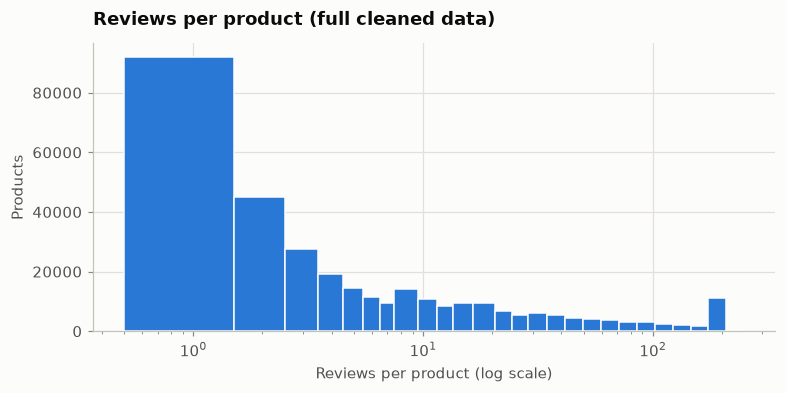

In [33]:
# Bin edges sit between whole numbers, so every count of reviews falls clearly inside one bin
edges = np.unique(np.round(np.logspace(0, np.log10(250), 32))) - 0.5

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(per_product, bins=edges, color=plotting.SERIES[0], edgecolor=plotting.SURFACE)
ax.set_xscale("log")
ax.set_xlabel("Reviews per product (log scale)")
ax.set_ylabel("Products")
ax.set_title("Reviews per product (full cleaned data)")
plotting.save(fig, "reviews_per_product")
plt.show()

### 5.2 Missing values (A2)

Covered in sections 2.2, 2.3 and 4.7. In short: the review body is almost never missing (845 reviews), the
missing seller is fully explained by non-buyers, and missing recommendation labels follow a clear pattern
(non-buyers, a spike in 1401, less popular products), so they are not missing at random.

### 5.3 Target distributions (A3)

In [34]:
def class_table(values, order):
    table = values.fillna("missing").value_counts().reindex(order).to_frame("reviews")
    table["pct"] = 100 * table["reviews"] / len(values)
    return table


recommendation_table = class_table(
    data["recommendation"], ["recommended", "no_idea", "not_recommended", "missing"]
)
band_table = class_table(data["rating_band"], ["low", "medium", "high", "missing"])
display(recommendation_table, band_table)

,reviews,pct
recommendation,,
recommended,4160043,67.62
no_idea,593625,9.65
not_recommended,504444,8.20
missing,893858,14.53


,reviews,pct
rating_band,,
low,562713,9.15
medium,1058360,17.20
high,4001982,65.05
missing,528915,8.60


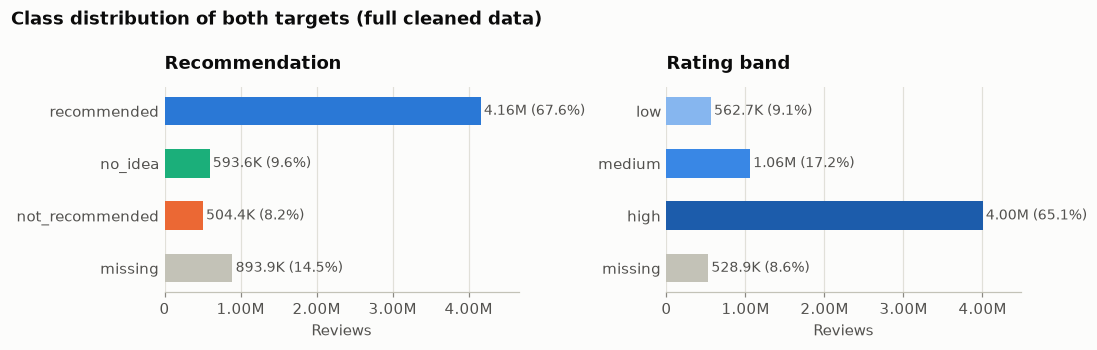

In [35]:
band_colors = {**plotting.RATING_BAND_COLORS, "missing": plotting.NEUTRAL}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, table, colors, title in [
    (axes[0], recommendation_table, plotting.RECOMMENDATION_COLORS, "Recommendation"),
    (axes[1], band_table, band_colors, "Rating band"),
]:
    plotting.hbar(
        ax,
        labels=list(table.index),
        values=list(table["reviews"]),
        colors=[colors[c] for c in table.index],
        value_labels=[
            f"{plotting.compact(n)} ({p:.1f}%)" for n, p in zip(table["reviews"], table["pct"], strict=True)
        ],
        xlabel="Reviews",
    )
    ax.set_title(title)
    ax.xaxis.set_major_formatter(lambda v, _: plotting.compact(v))
fig.suptitle("Class distribution of both targets (full cleaned data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plotting.save(fig, "target_distributions")
plt.show()

In [36]:
rate = data["rate"][data["rate"] <= 5]
rate_stats = pd.DataFrame(
    {
        "all valid ratings": rate.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
        "without zeros": rate[rate > 0].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]),
    }
)
rate_stats.loc["distinct values"] = [rate.nunique(), rate[rate > 0].nunique()]
rate_stats.loc["fractional (%)"] = [100 * (rate % 1 != 0).mean(), 100 * (rate[rate > 0] % 1 != 0).mean()]
rate_stats

,all valid ratings,without zeros
count,"6,151,969","5,623,055"
mean,3.65,3.99
std,1.57,1.15
min,0,0.05
5%,0,1
25%,3,3
50%,4,4
75%,5,5
95%,5,5
max,5,5


Both targets are imbalanced. Among labeled reviews, `recommended` outnumbers `not_recommended` about 8 to 1,
and `high` makes up two thirds of all reviews. This is why Macro F1 and per-class metrics are the main metrics,
and why class weights are considered during training.

The raw `rate` is only used to build `rating_band`. It is never a model input: it is the source of one target,
so feeding it to the model would hand over the answer, and the project brief allows only the review text as input.

### 5.4 Review length (A4)

In [37]:
data["chars"] = data["body"].str.len()
data["words"] = data["body"].str.count(r"\S+")

data[["chars", "words"]].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).T

,count,mean,std,min,50%,75%,90%,95%,99%,max
chars,"6,151,970",48.38,64.28,1,29,57,106,152,296,"4,000"
words,"6,151,970",10.08,13.35,1,6,12,22,32,62,908


In [38]:
# Is there an upper limit on review length?
pd.Series(
    {
        "reviews with exactly 4,000 characters": (data["chars"] == 4000).sum(),
        "reviews with 3,900-3,999 characters": data["chars"].between(3900, 3999).sum(),
        "reviews over 500 characters": (data["chars"] > 500).sum(),
    },
    name="reviews",
).to_frame()

,reviews
"reviews with exactly 4,000 characters",10
"reviews with 3,900-3,999 characters",3
reviews over 500 characters,14020


In [39]:
length_groups = pd.Series(
    {
        "1-2 words": (data["words"] <= 2).sum(),
        "3-10 words": data["words"].between(3, 10).sum(),
        "11-50 words": data["words"].between(11, 50).sum(),
        "51-200 words": data["words"].between(51, 200).sum(),
        "more than 200 words": (data["words"] > 200).sum(),
    },
    name="reviews",
).to_frame()
length_groups["pct"] = 100 * length_groups["reviews"] / len(data)
length_groups

,reviews,pct
1-2 words,1021847,16.61
3-10 words,3347775,54.42
11-50 words,1678056,27.28
51-200 words,102472,1.67
more than 200 words,1820,0.03


In [40]:
percentiles = [0.5, 0.9, 0.95, 0.99]
words_by_label = data.groupby(data["recommendation"].fillna("missing"))["words"].describe(
    percentiles=percentiles
)
words_by_band = data.groupby(data["rating_band"].fillna("missing"))["words"].describe(percentiles=percentiles)
display(words_by_label.loc[LABELS], words_by_band.loc[["low", "medium", "high", "missing"]])

,count,mean,std,min,50%,90%,95%,99%,max
recommendation,,,,,,,,,
recommended,"4,160,043",9.23,12.08,1,6,20,28,56,908
no_idea,"593,625",12.36,14.90,1,8,27,38,70,696
not_recommended,"504,444",15.16,16.71,1,10,33,45,79,623
missing,"893,858",9.68,14.85,1,5,22,32,67,853


,count,mean,std,min,50%,90%,95%,99%,max
rating_band,,,,,,,,,
low,"562,713",14.08,16.26,1,9,31,43,77,824
medium,"1,058,360",11.11,14.48,1,7,24,35,68,853
high,"4,001,982",9.14,12.47,1,5,20,28,57,908
missing,"528,915",10.89,13.03,1,7,24,33,61,625


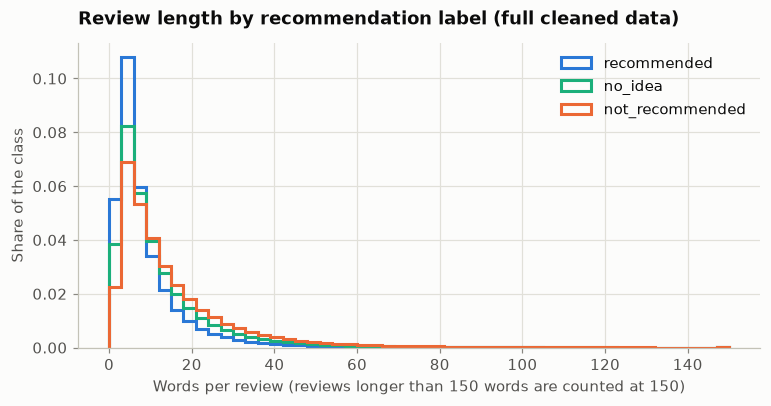

In [41]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = range(0, 151, 3)
for label in ["recommended", "no_idea", "not_recommended"]:
    words = data.loc[data["recommendation"] == label, "words"].clip(upper=150)
    ax.hist(
        words,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=plotting.RECOMMENDATION_COLORS[label],
        label=label,
    )
ax.set_xlabel("Words per review (reviews longer than 150 words are counted at 150)")
ax.set_ylabel("Share of the class")
ax.legend(loc="upper right")
ax.set_title("Review length by recommendation label (full cleaned data)")
plotting.save(fig, "length_by_label")
plt.show()

### 5.5 Repeated texts and product concentration (A5)

Duplicate ids were handled in section 2.5. Here the question is about the **text**: how often the exact same
review text appears, whether identical texts carry different labels, and whether the same text shows up on
different products. The last point matters for the split: if a short text like "عالی" appears in both the
training and the test products, the test score partly measures memorization.

Texts are compared after stripping surrounding whitespace, using a hash of each text instead of the text itself
to save memory.

In [42]:
data["text_key"] = pd.util.hash_pandas_object(data["body"].str.strip(), index=False)

text_counts = data["text_key"].value_counts()
repeated = data["text_key"].map(text_counts) > 1
pd.Series(
    {
        "distinct texts": len(text_counts),
        "texts that appear more than once": (text_counts > 1).sum(),
        "reviews whose text appears elsewhere": repeated.sum(),
        "share of reviews (%)": round(100 * repeated.mean(), 2),
    },
    name="value",
).to_frame()

,value
distinct texts,"4,054,477"
texts that appear more than once,"190,077"
reviews whose text appears elsewhere,"2,287,570"
share of reviews (%),37.18


In [43]:
# The 15 most frequent texts
top_keys = text_counts.head(15)
top_texts = data.loc[data["text_key"].isin(top_keys.index)].drop_duplicates("text_key").set_index("text_key")
top_products = data.loc[data["text_key"].isin(top_keys.index)].groupby("text_key")["product_id"].nunique()
pd.DataFrame(
    {
        "text": top_texts.loc[top_keys.index, "body"].str[:60].values,
        "reviews": top_keys.values,
        "products": top_products.loc[top_keys.index].values,
    }
)

,text,reviews,products
0,عالی,134623,60172
1,خوب بود,89915,47418
2,خوبه,83629,41497
3,خوب,70662,39628
4,عالی بود,30548,23332
5,عالیه,23430,18294
6,خیلی خوب بود,17536,14524
7,پیشنهاد میکنم,15398,13183
8,معمولی \n,15141,12136
9,خیلی خوبه,12443,10657


In [44]:
products_per_text = data.groupby("text_key")["product_id"].nunique()
on_several_products = data["text_key"].map(products_per_text) > 1

labeled = data[data["recommendation"].notna()]
labels_per_text = labeled.groupby("text_key")["recommendation"].nunique()
conflicting = labeled["text_key"].map(labels_per_text) > 1

banded = data[data["rating_band"].notna()]
bands_per_text = banded.groupby("text_key")["rating_band"].nunique()
conflicting_band = banded["text_key"].map(bands_per_text) > 1

pd.Series(
    {
        "reviews whose text appears on 2+ products": on_several_products.sum(),
        "  share of all reviews (%)": round(100 * on_several_products.mean(), 2),
        "labeled reviews whose text has 2+ different labels": conflicting.sum(),
        "  share of labeled reviews (%)": round(100 * conflicting.mean(), 2),
        "banded reviews whose text has 2+ different bands": conflicting_band.sum(),
        "  share of banded reviews (%)": round(100 * conflicting_band.mean(), 2),
    },
    name="value",
).to_frame()

,value
reviews whose text appears on 2+ products,"2,286,559"
share of all reviews (%),37.17
labeled reviews whose text has 2+ different labels,"1,309,121"
share of labeled reviews (%),24.90
banded reviews whose text has 2+ different bands,"1,728,191"
share of banded reviews (%),30.73


In [45]:
def majority_agreement(frame, label):
    """Share of reviews whose label equals the most common label of their exact text.

    No model that sees only the text can beat this on these reviews, because identical texts get identical
    predictions.
    """
    pair_counts = frame.value_counts(["text_key", label])
    return pair_counts.groupby(level="text_key").max().sum() / len(frame)


short = data["words"] <= 2
pd.DataFrame(
    {
        "all reviews": [
            majority_agreement(labeled, "recommendation"),
            majority_agreement(banded, "rating_band"),
        ],
        "1-2 word reviews": [
            majority_agreement(labeled[short.loc[labeled.index]], "recommendation"),
            majority_agreement(banded[short.loc[banded.index]], "rating_band"),
        ],
    },
    index=["recommendation", "rating band"],
).mul(100).round(1)

,all reviews,1-2 word reviews
recommendation,97.50,92.30
rating band,94.60,85.80


In [46]:
# The labels given to the single most frequent text
excellent = data.loc[data["body"].str.strip() == "عالی"]
pd.DataFrame(
    {
        "recommendation (%)": excellent["recommendation"].value_counts(normalize=True, dropna=False),
        "rating band (%)": excellent["rating_band"].value_counts(normalize=True, dropna=False),
    }
).mul(100).round(1)

,recommendation (%),rating band (%)
high,NaN,94.40
low,NaN,1
medium,NaN,2.10
no_idea,0.50,NaN
not_recommended,0.20,NaN
recommended,69.90,NaN
NaN,29.40,2.60


In [47]:
sorted_counts = per_product.sort_values(ascending=False).to_numpy()
cumulative_reviews = 100 * sorted_counts.cumsum() / sorted_counts.sum()
share_of_products = 100 * np.arange(1, len(sorted_counts) + 1) / len(sorted_counts)


def top_share(pct):
    n = int(len(sorted_counts) * pct / 100)
    return round(100 * sorted_counts[:n].sum() / sorted_counts.sum(), 1)


pd.Series(
    {f"top {p}% of products": top_share(p) for p in [1, 5, 10, 20, 50]},
    name="share of reviews (%)",
).to_frame()

,share of reviews (%)
top 1% of products,10.80
top 5% of products,48.10
top 10% of products,67.10
top 20% of products,82.40
top 50% of products,95.60


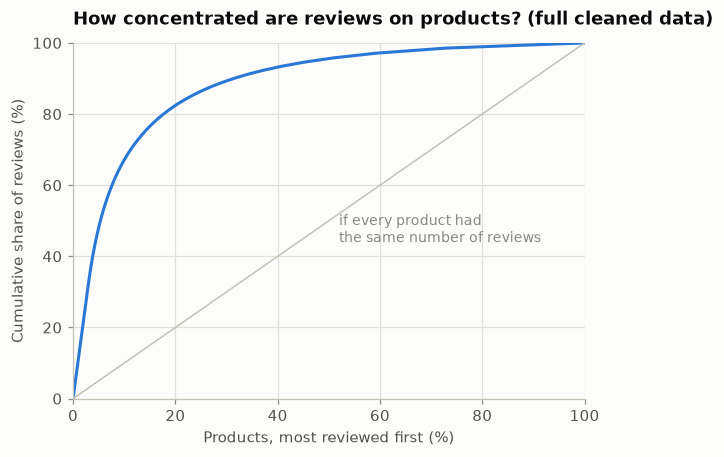

In [48]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(share_of_products, cumulative_reviews, color=plotting.SERIES[0])
ax.plot([0, 100], [0, 100], color=plotting.NEUTRAL, linewidth=1)
ax.text(52, 44, "if every product had\nthe same number of reviews", color=plotting.MUTED, fontsize=9)
ax.set_xlabel("Products, most reviewed first (%)")
ax.set_ylabel("Cumulative share of reviews (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("How concentrated are reviews on products? (full cleaned data)")
plotting.save(fig, "product_concentration")
plt.show()

### 5.6 Findings

**Reviews were collected with a cap of about 200 per product.** 8,346 products have exactly 200 reviews, against
about 77 for each count between 190 and 199. A smaller group spills over the cap (1,088 products with 201-210
reviews, at most 233). The product with 400 raw rows has just 200 distinct review ids: it was collected twice,
and cleaning removed the copies. So the review counts of popular products are cut off.

**Reviews are concentrated on few products.** Half of the products have 4 reviews or fewer, while the top 10% of
products hold 67% of all reviews. With a random row-level split, reviews of the same popular product would land
in both train and test, and the model could pick up product-specific words (brand, model, size) instead of
opinion. **This is the reason for splitting by product.**

**Both targets are imbalanced.** `recommended` is 67.6% of all reviews (about 8 times `not_recommended`), and
`high` is 65.1%. After the zero-rating decision, `low` is the smallest class at 9.1%. Macro F1, per-class metrics
and class weights follow from this.

**Without the zeros, the rating distribution changes a lot.** With zeros, the mean rating is 3.65 (std 1.57);
without them it is 3.99 (std 1.15).

**Reviews are short.** The median review has 6 words (29 characters); 95% have at most 32 words and 99% at most
62. One review in six (16.6%) is just one or two words, such as `عالی` or `خوب بود`. The longest reviews stop at
4,000 characters (10 reviews hit exactly that length, against 3 between 3,900 and 3,999), which suggests the
site limits review length. A short `max_length` covers almost every review, which makes Transformer training
much cheaper. Longer reviews are cut at the end, keeping the beginning; if `max_length` covers the 99th percentile
(62 words), this affects fewer than 1% of reviews.
The exact `max_length` is chosen in the fine-tuning notebook, from token counts measured with the chosen tokenizer.

**Unhappy reviewers write more.** The median `not_recommended` review has 10 words, against 6 for `recommended`;
`low` reviews are also longer than `high` ones. Length carries some signal, which the error analysis should keep
in mind (short negative reviews may be harder).

**Many texts repeat, but mostly with the same label.**

- 37% of reviews have a text that appears somewhere else; `عالی` alone appears 134,623 times on 60,172 products.
- 25% of labeled reviews have a text that appears with more than one label somewhere. This sounds high but is
  driven by very common texts: `عالی` is `recommended` in 99% of its labeled copies, and almost every copy that
  has a band is `high`.
- A better measure is how often a review agrees with the most common label of its exact text. That is an accuracy
  ceiling for any text-only model on these reviews: 97.5% for recommendation and 94.6% for rating band, falling to
  92.3% and 85.8% on one- or two-word reviews.

Identical texts will appear on both sides of any product split. The plan is to keep the test set as it is and
also report scores on test reviews whose text, after normalization, never appears in training.

Section 7 collects the decisions that follow from these findings.

## 6. Vocabulary (A6)

How do people phrase their opinions? This section looks at the raw text, before any normalization, for two
reasons: to see which characters and spellings a normalization step has to handle, and to check which words
carry the signal, especially negations, which the brief says must not be removed without evidence.

### 6.1 Characters that normalization has to deal with

The share of reviews that contain each kind of character or pattern (full cleaned data).

In [49]:
import re

body = data["body"]
patterns = {
    "Arabic yeh (ي)": "ي",
    "Arabic kaf (ك)": "ك",
    "Persian digits (۰-۹)": "[۰-۹]",
    "Arabic digits (٠-٩)": "[٠-٩]",
    "Latin digits (0-9)": "[0-9]",
    "Latin letters": "[A-Za-z]",
    "zero-width non-joiner (half-space)": "‌",
    "other invisible characters": "[​‍‎‏﻿]",
    "tatweel / kashida (ـ)": "ـ",
    "line breaks": "[\r\n]",
    "emoji": "[\U0001f300-\U0001faff☀-➿]",
    "URL": r"https?://|www\.",
    "HTML tag": r"<[A-Za-z/][^>]*>",
}
characters = pd.Series({name: 100 * body.str.contains(pattern).mean() for name, pattern in patterns.items()})

# "The same letter three times in a row" needs a backreference, which only Python's own re module supports
REPEATED_LETTER = re.compile(r"([^\W\d_])\1\1")
has_repeat = body.map(lambda text: REPEATED_LETTER.search(text) is not None)
characters["same letter 3+ times (خیییلی)"] = 100 * has_repeat.mean()
characters = characters.sort_values(ascending=False)
characters.to_frame("share of reviews (%)")

,share of reviews (%)
line breaks,9.21
Persian digits (۰-۹),3.16
zero-width non-joiner (half-space),3.14
same letter 3+ times (خیییلی),2.08
Latin digits (0-9),1.56
Arabic yeh (ي),0.79
emoji,0.76
Latin letters,0.65
Arabic kaf (ك),0.41
tatweel / kashida (ـ),0.04


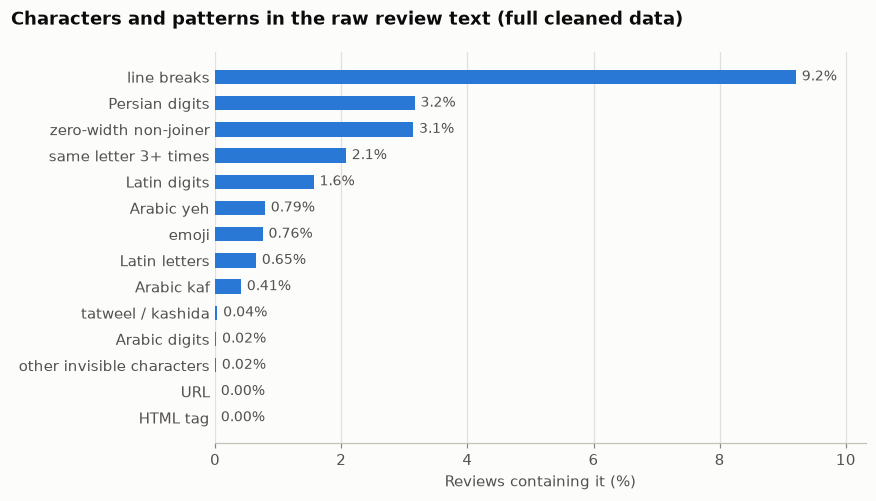

In [50]:
fig, ax = plt.subplots(figsize=(8, 4.6))
plotting.hbar(
    ax,
    labels=[name.split(" (")[0] for name in characters.index],  # examples in Persian stay in the table
    values=list(characters),
    value_labels=[f"{v:.2f}%" if v < 1 else f"{v:.1f}%" for v in characters],
    xlabel="Reviews containing it (%)",
)
fig.suptitle(
    "Characters and patterns in the raw review text (full cleaned data)", x=0.01, ha="left", fontweight="bold"
)
fig.tight_layout()
plotting.save(fig, "character_audit")
plt.show()

### 6.2 Most frequent words and word pairs

Word counts use **1,000,000 reviews**: a simple random sample without replacement from the cleaned table (the single rating of 2500 dropped), drawn with `DataFrame.sample(n, random_state=2026)`. At this size the rankings are stable.
Words are split on anything that is not a letter or digit, so a half-space splits `نمی‌خرم` into `نمی` and `خرم`.

In [51]:
from sklearn.feature_extraction.text import CountVectorizer

sample = data.sample(1_000_000, random_state=2026)[["body", "recommendation", "rating_band"]]
del data, body  # the full table is not needed any more

word_vectorizer = CountVectorizer(token_pattern=r"(?u)\b\w+\b", min_df=5)
word_counts = word_vectorizer.fit_transform(sample["body"])
words = word_vectorizer.get_feature_names_out()

pair_vectorizer = CountVectorizer(token_pattern=r"(?u)\b\w+\b", ngram_range=(2, 2), min_df=20)
pair_counts = pair_vectorizer.fit_transform(sample["body"])
pairs = pair_vectorizer.get_feature_names_out()

top_words = pd.Series(np.asarray(word_counts.sum(axis=0)).ravel(), index=words).nlargest(20)
top_pairs = pd.Series(np.asarray(pair_counts.sum(axis=0)).ravel(), index=pairs).nlargest(20)
print(f"Distinct words (5+ uses): {len(words):,} | distinct word pairs (20+ uses): {len(pairs):,}")
pd.DataFrame(
    {
        "word": top_words.index,
        "count": top_words.values,
        "word pair": top_pairs.index,
        "pair count": top_pairs.values,
    }
)

Distinct words (5+ uses): 27,029 | distinct word pairs (20+ uses): 46,051


,word,count,word pair,pair count
0,و,447822,خوب بود,72296
1,بود,228771,نسبت به,37819
2,خیلی,219736,عالی بود,30201
3,خوب,179483,خوب و,28262
4,به,174492,خیلی خوبه,27234
5,از,158175,خوبی داره,27201
6,خوبه,154729,خیلی خوب,24536
7,که,140598,دیجی کالا,22475
8,عالی,131318,در کل,19984
9,من,126603,بود و,19693


### 6.3 Words that separate the classes

For each word, the ratio between how often it appears in one class and how often in the other, on a log scale
(with +1 smoothing, and only for words used at least 200 times in the sample). A large positive value means the
word is typical of the first class.

In [52]:
def distinctive_words(counts, vocabulary, in_a, in_b, min_count=200, top=15):
    """Words most typical of group a and of group b, by smoothed log frequency ratio."""
    count_a = np.asarray(counts[in_a.to_numpy()].sum(axis=0)).ravel()
    count_b = np.asarray(counts[in_b.to_numpy()].sum(axis=0)).ravel()
    frequency_a = (count_a + 1) / (count_a.sum() + len(vocabulary))
    frequency_b = (count_b + 1) / (count_b.sum() + len(vocabulary))
    table = pd.DataFrame(
        {"count_a": count_a, "count_b": count_b, "log_ratio": np.log(frequency_a / frequency_b)}
    )
    table.index = vocabulary
    table = table[(table["count_a"] + table["count_b"]) >= min_count]
    return table.nlargest(top, "log_ratio"), table.nsmallest(top, "log_ratio")


is_recommended = sample["recommendation"] == "recommended"
is_not_recommended = sample["recommendation"] == "not_recommended"
positive_words, negative_words = distinctive_words(word_counts, words, is_recommended, is_not_recommended)
high_words, low_words = distinctive_words(
    word_counts, words, sample["rating_band"] == "high", sample["rating_band"] == "low"
)
pd.DataFrame(
    {
        "recommended": positive_words.index,
        "not_recommended": negative_words.index,
        "high band": high_words.index,
        "low band": low_words.index,
    }
)

,recommended,not_recommended,high band,low band
0,عالیییی,پولتونو,عالیییی,پولتونو
1,عاشقشم,مزخرف,عالییییییی,مزخرف
2,گوگولی,افتضاحه,عالییییییییی,متاسفم
3,کیوته,افتضاح,کیوته,افتضاح
4,وکاربردی,متاسفم,عالیییییییییی,افتضاحه
5,عالییییی,نخور,العادس,نخور
6,عاشقش,پولتون,عاشقشم,بدترین
7,عااااالی,بدترین,عاشقش,پولتون
8,راضیم,نخرید,گوگولی,آشغال
9,عالیهههه,پشیمونم,نظیر,نریزید


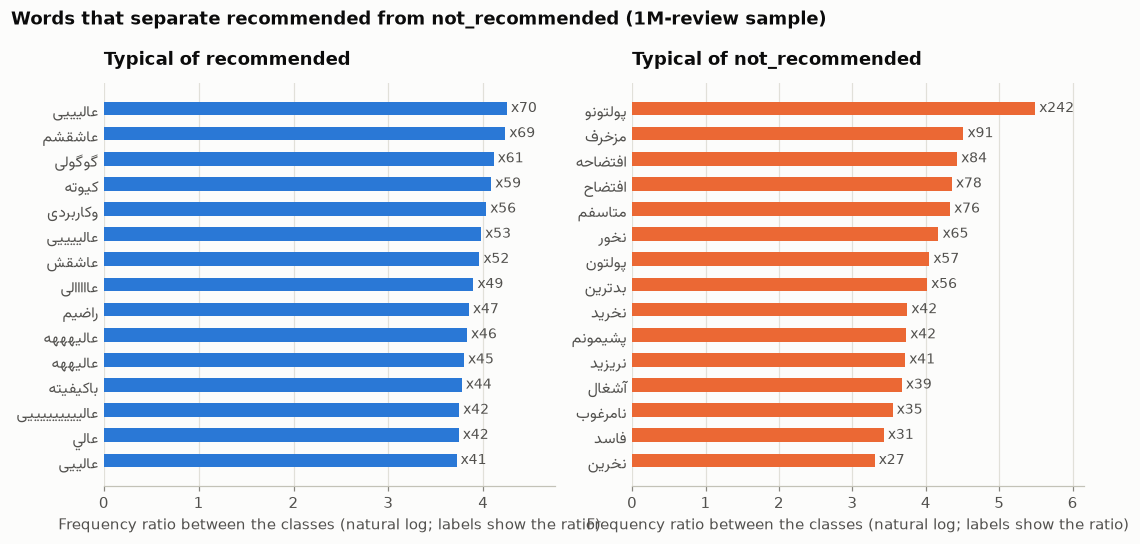

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, table, color, title in [
    (axes[0], positive_words, plotting.RECOMMENDATION_COLORS["recommended"], "Typical of recommended"),
    (
        axes[1],
        negative_words,
        plotting.RECOMMENDATION_COLORS["not_recommended"],
        "Typical of not_recommended",
    ),
]:
    strength = table["log_ratio"].abs()
    plotting.hbar(
        ax,
        labels=list(table.index),
        values=list(strength),
        colors=color,
        value_labels=[f"x{np.exp(v):.0f}" for v in strength],
        xlabel="Frequency ratio between the classes (natural log; labels show the ratio)",
    )
    plotting.use_persian_ticks(ax)
    ax.set_title(title)
fig.suptitle(
    "Words that separate recommended from not_recommended (1M-review sample)",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
plotting.save(fig, "distinctive_words")
plt.show()

### 6.4 Negation words

Negation flips the meaning of a sentence (`خوب بود` vs `خوب نبود`). The share of reviews in each class that
contain at least one common negation word. Advice words such as `نخرید` ("don't buy") are left out on purpose:
they are negative opinions, not negation.

In [54]:
NEGATIONS = [
    "نه", "نیست", "نیستم", "نبود", "نشد", "نکرد", "نداره", "ندارد", "نداشت",
    "نمی", "نمیشه", "نمیکنه", "نمیکنم", "نکنید",
]  # fmt: skip
negation_columns = [word_vectorizer.vocabulary_[w] for w in NEGATIONS if w in word_vectorizer.vocabulary_]
sample["has_negation"] = np.asarray(word_counts[:, negation_columns].sum(axis=1)).ravel() > 0

negation_by_label = sample.groupby(sample["recommendation"].fillna("missing"))["has_negation"].mean() * 100
negation_by_band = sample.groupby(sample["rating_band"].fillna("missing"))["has_negation"].mean() * 100
display(
    negation_by_label.loc[LABELS].to_frame("with negation (%)"),
    negation_by_band.loc[["low", "medium", "high", "missing"]].to_frame("with negation (%)"),
)

,with negation (%)
recommendation,
recommended,8.81
no_idea,33.79
not_recommended,42.22
missing,11.83


,with negation (%)
rating_band,
low,38.98
medium,24.67
high,8.32
missing,13.62


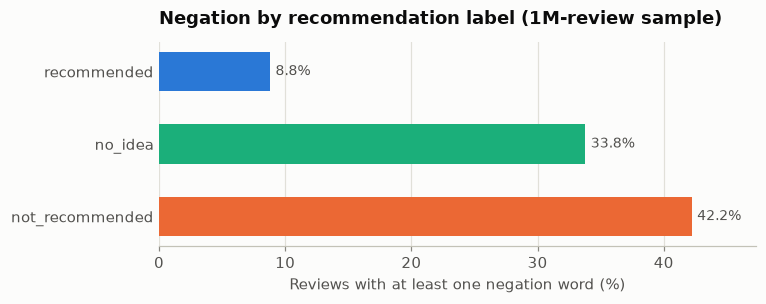

In [55]:
shown = negation_by_label.loc[["recommended", "no_idea", "not_recommended"]]
fig, ax = plt.subplots(figsize=(7, 2.4))
plotting.hbar(
    ax,
    labels=list(shown.index),
    values=list(shown),
    colors=[plotting.RECOMMENDATION_COLORS[c] for c in shown.index],
    value_labels=[f"{v:.1f}%" for v in shown],
    xlabel="Reviews with at least one negation word (%)",
)
ax.set_title("Negation by recommendation label (1M-review sample)")
plotting.save(fig, "negation_by_label")
plt.show()

### 6.5 Labeled vs naturally unlabeled reviews

Section 4 showed that unlabeled reviews come from different users and years. Do they also use different words?

In [56]:
unlabeled_words, labeled_words = distinctive_words(
    word_counts, words, sample["recommendation"].isna(), sample["recommendation"].notna(), top=20
)
pd.DataFrame({"typical of unlabeled": unlabeled_words.index, "typical of labeled": labeled_words.index})

,typical of unlabeled,typical of labeled
0,موجودش,پاپکو
1,نخریدم,عکسشو
2,لطفا,میذارم
3,موجود,سوتین
4,بگذارید,مرجوعش
5,نگرفتم,متاسفم
6,خواهش,بفرستن
7,بیارید,کوچکتره
8,عطرهای,سایزم
9,خواهشا,عکسشم


In [57]:
# How many unlabeled reviews are requests (please bring it back, please restock) rather than opinions?
REQUEST = "لطفا|لطفاً|خواهش|موجود کنید|موجودش کنید|بیارید|بذارید|بزارید|بگذارید"
group = sample["recommendation"].isna().map({True: "unlabeled", False: "labeled"})
has_request = sample["body"].str.contains(REQUEST)
(has_request.groupby(group).mean() * 100).round(1).to_frame("with a request word (%)")

,with a request word (%)
recommendation,
labeled,0.40
unlabeled,1.70


### 6.6 Which product categories are covered?

Words like `فاسد` ("spoiled") raise the question of what kinds of products the reviews are about. The products
file has a top-level `sub_category` column; each product gets its most frequent value.

In [58]:
from digikala_reviews.config import PRODUCTS_RAW_DIR

products_raw = pd.read_parquet(PRODUCTS_RAW_DIR, columns=["id", "sub_category", "Category1"])
products_raw["id"] = products_raw["id"].astype("int64")
# Most frequent category per product. Count (id, category) pairs and keep the top one for each id;
# ties are broken alphabetically so the result is the same on every run.
pair_counts = products_raw.value_counts(["id", "sub_category"]).reset_index()
pair_counts = pair_counts.sort_values(["id", "count", "sub_category"], ascending=[True, False, True])
category = pair_counts.drop_duplicates("id").set_index("id")["sub_category"]

review_products = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["product_id"])["product_id"]
review_category = review_products.map(category).rename("category")
coverage = review_category.value_counts().to_frame("reviews")
coverage["pct"] = 100 * coverage["reviews"] / len(review_category)
coverage["products in the file"] = category.value_counts()
coverage["reviewed products"] = category.loc[review_products.unique()].value_counts()
coverage

,reviews,pct,products in the file,reviewed products
category,,,,
beauty,2249206,36.56,117217,67366
book & stationary & art,1512160,24.58,274326,94067
clothe,1475451,23.98,442577,126613
toys and kids,602327,9.79,66339,29769
travel,162473,2.64,23777,6297
rural goods,150353,2.44,24116,7473


In [59]:
# What are "rural goods"? The largest second-level groups inside it
rural = products_raw.loc[products_raw["sub_category"] == "rural goods"].drop_duplicates("id")
rural["Category1"].value_counts().head(5).to_frame("products")

,products
Category1,
مواد غذایی,14314
تنقلات خانگی,1035
اصلاح موی صورت,879
صبحانه محلی,869
سشوار,706


### 6.7 Findings

**The raw text needs a small, evidence-based normalization step.** Measured on all 6,151,970 cleaned reviews:

| Pattern | Reviews | What normalization should do |
|---|---:|---|
| Line breaks | 9.2% | Replace with a space |
| Persian digits / Latin digits / Arabic digits | 3.2% / 1.6% / 0.02% | Map all digits to one script |
| Zero-width non-joiner (half-space) | 3.1% | Keep it as part of the word, but write it consistently |
| Same letter 3+ times (`عالیییی`) | 2.1% | Shorten long repeats |
| Arabic `ي` / `ك` | 0.8% / 0.4% | Map to Persian `ی` / `ک` |
| Emoji | 0.8% | Keep: they often carry sentiment |
| Latin letters | 0.7% | Keep (brand and model names) |
| Tatweel, other invisible characters | < 0.05% | Remove |
| URLs, HTML tags | ~0% | Nothing to do |

The distinctive-word chart shows why this matters: almost half of the words typical of `recommended` are spellings
of `عالی` with extra letters, and `عالي` with an Arabic yeh appears as a separate word. Without normalization a
model sees these as unrelated words.

**The words that separate the classes are clear.** Reviews that do not recommend a product use `پولتونو` (from
"don't waste your money"), `مزخرف`, `افتضاح`, `نخرید`, `پشیمونم`, `آشغال` and `فاسد`; some appear 30 to 240 times
more often than in recommended reviews. The high/low split shows the same words. Many of them are colloquial
(`پشیمونم` rather than `پشیمانم`, `پولتونو`), so the model has to cope with informal Persian. Some joined forms
like `وکاربردی` ("and practical", written without a space) also show up. Splitting a leading `و` by rule would
break many real words, so this is left to the tokenizer and to character n-grams in the baseline.

**Negation words must stay.** At least one negation word appears in 42.2% of `not_recommended` reviews, 33.8% of
`no_idea` and only 8.8% of `recommended`; for the bands it is 39.0% (`low`), 24.7% (`medium`) and 8.3% (`high`).
Removing them would delete one of the clearest signals in the data.

**Stopword removal is risky here.** The most frequent words are function words (`و`, `به`, `از`, `که`), but the
list also includes `خیلی` ("very"), `ولی` ("but", typical of mixed opinions) and negations, which a generic stopword
list would remove. Removing stopwords is therefore tested as an experiment with the TF-IDF baseline, not applied
by default.

**Unlabeled reviews contain more requests, but most do not contain one.** Their most typical words include
`موجودش`, `لطفا`, `بیارید` and `خواهش` (please restock, please bring it back). Request words are four times more
common in unlabeled reviews than in labeled ones (1.7% against 0.4%), but they are still rare, so the difference
in vocabulary is real but small. Together with section 4.7, this is another reason not to treat the naturally
unlabeled pool as a sample of the labeled data.

**The data covers six product groups only.** By share of reviews: beauty (36.6%), books and stationery (24.6%),
clothing (24.0%), toys and kids (9.8%), travel (2.6%) and local goods (2.4%). Clothing has the most products
(442,577 in the file), but beauty products collect the most reviews. The largest group inside local goods is food,
which explains words like `فاسد` ("spoiled"). Apart from a few small personal-care appliances under local goods, there are no
electronics, phones or home appliances, so results should not be assumed to carry over to those categories. Scores per category are reported in the error analysis.

## 7. Decisions for the next stages

Every decision below comes from a finding in this notebook. They are fixed now, before any model is trained,
so that model results cannot influence them. Comparisons planned with the baseline (for example both zero-rating
rules) are reported, but they do not change these decisions.

| Area | Decision | Evidence |
|---|---|---|
| Cleaning | Exclude empty bodies and conflicting duplicate ids; keep one copy of other duplicates | 2.2, 2.5, 3 |
| Rating band | Bands from ratings in (0, 5]: `low` < 2.5 ≤ `medium` < 4.0 ≤ `high`; a rating of 0 or above 5 gets no band | 2.4, 4.1-4.5, 4.8 |
| Fractional ratings | Kept as real ratings, banded unchanged | 4.6 |
| Split | One split for both tasks, grouped by product, 70/15/15, stratified on both targets | 5.5, 5.6 |
| Repeated texts | Keep the test set as is, and also report scores on test reviews whose normalized text never appears in training | 5.5, 5.6 |
| Metrics | Macro F1 and per-class precision, recall and F1 as the main metrics; balanced accuracy and ordinal error for bands | 5.3 |
| Class imbalance | Class weights computed on the training split | 5.3 |
| Semi-supervised | Main experiment uses the random mask defined in the project brief; naturally unlabeled reviews only as an extension | 4.7, 6.5 |
| Zero-rated reviews | A candidate pool for pseudo-labeling the rating band later, training split only | 4.8 |
| Normalization | Map Arabic `ي`/`ك` and all digits, replace line breaks, shorten repeated letters, remove tatweel and invisible characters, keep half-spaces consistent | 6.1, 6.7 |
| Emoji | Kept in the text | 6.1, 6.7 |
| Negation | Never removed | 6.4 |
| Stopwords | Not removed by default; removal tested as an experiment on the TF-IDF baseline | 6.2, 6.7 |
| Joined words | Not split by rule; character n-grams tested on the TF-IDF baseline | 6.3, 6.7 |
| Input length | Short `max_length`, set from token counts with the chosen tokenizer; longer reviews keep their beginning | 5.4, 5.6 |
| Evaluation by group | Scores reported per product category and per text length; no claim for electronics or appliances | 5.4, 6.6 |
| Expected ceiling | Scores are read against the text-only accuracy ceiling (97.5% recommendation, 94.6% rating band) | 5.5, 5.6 |